<a href="https://colab.research.google.com/github/Mathanprasath-T/TrafficRoute/blob/main/emergence_dispatch_%26_traffic_route.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EMERGENCY DISPATCH TRAFFIC FORECASTING
Upload synthetic_traffic_benchmark_200k.csv


Saving synthetic_traffic_benchmark_200k.csv to synthetic_traffic_benchmark_200k (1).csv

Original dataset shape: (200000, 29)

Available columns:
['Record_ID', 'Timestamp', 'Date', 'Hour', 'Month', 'Day_of_Week', 'Time_of_Day', 'Is_Holiday', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Speed_Limit_kmh', 'Weather', 'Road_Condition', 'Visibility_m', 'Congestion_Index', 'Vehicle_Type', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh', 'Baseline_Expected_Response_Time_min', 'Accident_Occurred', 'Collision_Type', 'Vehicles_Involved', 'Accident_Severity', 'Dispatch_Priority', 'Actual_Response_Time_min', 'Road_Closure_Duration_min']

Selected records: 10000
Selected time range:
2022-01-01 00:26:51.921181523 to 2022-03-15 18:42:38.967695224

Missing values before preprocessing:
Intersection_Type        3412
Visibility_m              354
Driver_Experience_yrs     222
Collision_Type           9534
Dispatch_Priority        9534
dtype: int64

Hourly dataset shape: 

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │        10,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,785 (42.13 KB)

 Trainable params: 10,785 (42.13 KB)

 Non-trainable params: 0 (0.00 B)


JUSTIFICATION:
LSTM is suitable for sequential time-series data.
It learns temporal patterns from the previous 24 hours
to forecast the next hour's congestion index.

Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0589 - mae: 0.2017 - val_loss: 0.0396 - val_mae: 0.1489
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0414 - mae: 0.1642 - val_loss: 0.0321 - val_mae: 0.1389
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0366 - mae: 0.1520 - val_loss: 0.0283 - val_mae: 0.1317
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0312 - mae: 0.1399 - val_loss: 0.0231 - val_mae: 0.1192
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0287 - mae: 0.1339 - val_loss: 0.0223 - val_mae: 0.1166
Epoch 6/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0265 - mae: 0.1276 - val_loss: 0.0195 - val_mae: 0.1073
Epoch 7/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0243 - mae: 0.1213 - val_loss: 0.0181 - val_mae: 0.1026
Epoch 8/20
40

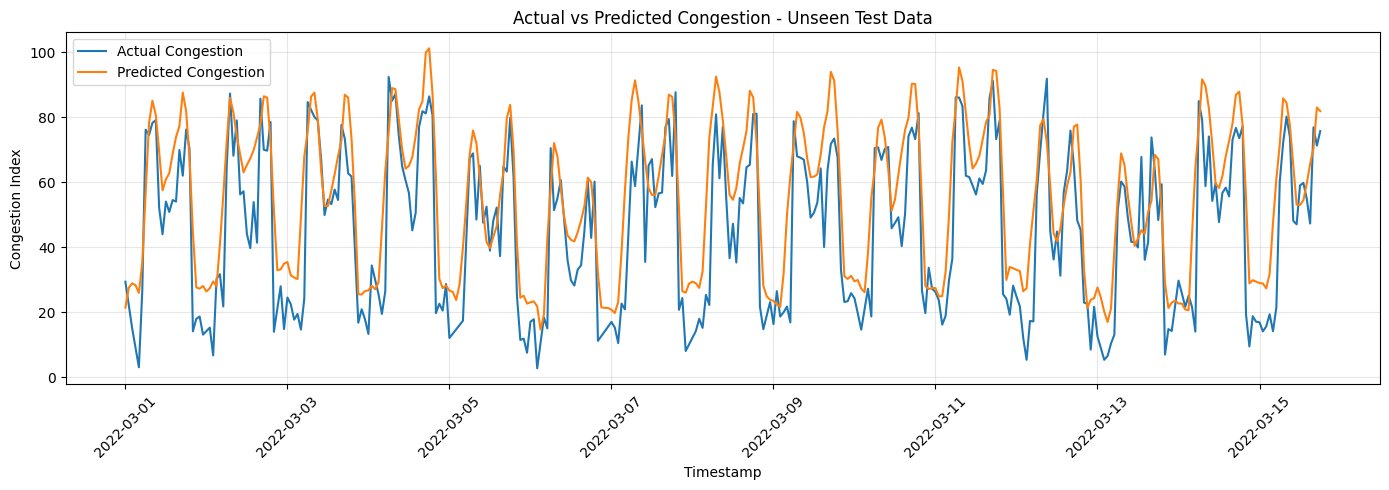

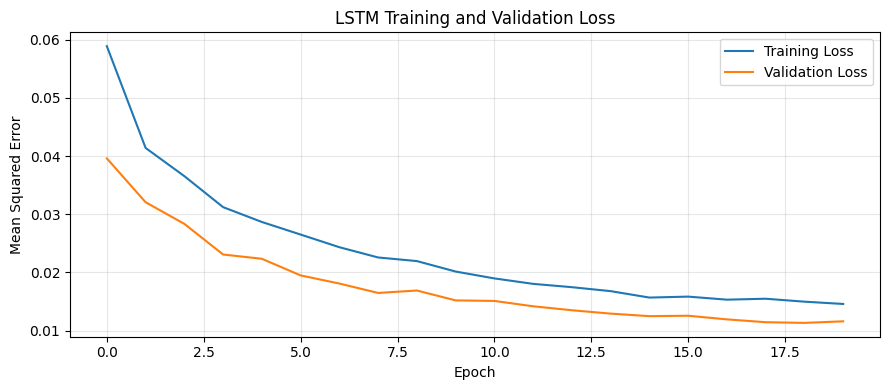


SAMPLE TEST PREDICTIONS
          Timestamp  Actual_Congestion_Index  Predicted_Congestion_Index  Absolute_Error
2022-03-01 00:00:00                29.400000                   21.420000        7.980000
2022-03-01 01:00:00                22.260000                   27.530001        5.270000
2022-03-01 02:00:00                15.120000                   28.900000       13.780000
2022-03-01 03:00:00                 9.110000                   28.350000       19.240000
2022-03-01 04:00:00                 3.100000                   25.959999       22.860001
2022-03-01 05:00:00                26.580000                   35.220001        8.640000
2022-03-01 06:00:00                76.150002                   56.669998       19.480000
2022-03-01 07:00:00                74.489998                   78.129997        3.650000
2022-03-01 08:00:00                78.220001                   85.029999        6.810000
2022-03-01 09:00:00                79.070000                   80.720001        1.650

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


ALL FIVE PRACTICAL TASKS COMPLETED.
This synthetic-data experiment is not validated for real ambulance routing.


In [2]:

# ============================================================
# EMERGENCY DISPATCH TRAFFIC CONGESTION FORECASTING
# Dataset: synthetic_traffic_benchmark_200k.csv
# Selected records: 10,000
# Model: LSTM Deep Learning
# ============================================================

import sys
import subprocess
import importlib.util

# Install required packages if needed
for module, package in [
    ("numpy", "numpy"),
    ("pandas", "pandas"),
    ("sklearn", "scikit-learn"),
    ("matplotlib", "matplotlib"),
    ("tensorflow", "tensorflow")
]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package]
        )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

print("=" * 65)
print("EMERGENCY DISPATCH TRAFFIC FORECASTING")
print("=" * 65)

# ------------------------------------------------------------
# STEP 1: UPLOAD AND LOAD YOUR DATASET
# ------------------------------------------------------------

print("Upload synthetic_traffic_benchmark_200k.csv")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No CSV file was uploaded.")

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("\nOriginal dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

# Check required columns
required_columns = [
    "Timestamp",
    "Congestion_Index"
]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Required column missing: {col}")

# Convert timestamps and remove invalid timestamp rows
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
df = df.dropna(subset=["Timestamp", "Congestion_Index"])

# Remove duplicate timestamps to avoid duplicate observations
df = df.sort_values("Timestamp")
df = df.drop_duplicates(subset=["Timestamp"], keep="first")

# ------------------------------------------------------------
# STEP 2: SELECT 10,000 CHRONOLOGICAL RECORDS
# Keep consecutive records from the beginning of the timeline.
# This preserves temporal order instead of random sampling.
# ------------------------------------------------------------

df = df.head(10000).copy()

if len(df) < 1000:
    raise ValueError("Too few valid records for sequence forecasting.")

print("\nSelected records:", len(df))
print("Selected time range:")
print(df["Timestamp"].min(), "to", df["Timestamp"].max())

print("\nMissing values before preprocessing:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# ------------------------------------------------------------
# STEP 3: SELECT RELEVANT FEATURES
# Avoid IDs and outcome variables that can cause data leakage.
# Target = Congestion_Index
# ------------------------------------------------------------

numeric_candidates = [
    "Hour",
    "Month",
    "Is_Holiday",
    "Speed_Limit_kmh",
    "Visibility_m",
    "Accident_Occurred",
    "Vehicles_Involved",
    "Recorded_Speed_kmh",
    "Road_Closure_Duration_min"
]

categorical_candidates = [
    "Day_of_Week",
    "Time_of_Day",
    "Area_Type",
    "Road_Type",
    "Intersection_Type",
    "Weather",
    "Road_Condition",
    "Vehicle_Type"
]

numeric_cols = [c for c in numeric_candidates if c in df.columns]
categorical_cols = [c for c in categorical_candidates if c in df.columns]

# Convert numeric features and fill missing values with medians
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].replace([np.inf, -np.inf], np.nan)
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with the most frequent category
for col in categorical_cols:
    df[col] = df[col].astype("object")
    mode_values = df[col].mode(dropna=True)
    fill_value = mode_values.iloc[0] if len(mode_values) else "Unknown"
    df[col] = df[col].fillna(fill_value).astype(str)

# Keep target numerical and complete
df["Congestion_Index"] = pd.to_numeric(
    df["Congestion_Index"], errors="coerce"
)
df = df.dropna(subset=["Congestion_Index"])

# ------------------------------------------------------------
# STEP 4: ENCODE CATEGORICAL FEATURES
# One-hot encoding changes text categories into numeric columns.
# ------------------------------------------------------------

numeric_features = df[numeric_cols].astype(float)

encoded_categories = pd.get_dummies(
    df[categorical_cols],
    prefix=categorical_cols,
    dtype=float
)

features = pd.concat(
    [numeric_features, encoded_categories],
    axis=1
)

features["Congestion_Index"] = df["Congestion_Index"].to_numpy()

# ------------------------------------------------------------
# STEP 5: GROUP DATA BY HOUR
# Aggregate records that belong to the same hour.
# Fill gaps in the hourly timeline using time interpolation.
# ------------------------------------------------------------

features.index = pd.DatetimeIndex(df["Timestamp"], name="Timestamp")
features = features.sort_index()

hourly = features.resample("h").mean()

# Create a complete hourly timeline
full_hours = pd.date_range(
    start=hourly.index.min().floor("h"),
    end=hourly.index.max().floor("h"),
    freq="h"
)

hourly = hourly.reindex(full_hours)
hourly.index.name = "Timestamp"

# Fill gaps between observations in time order
hourly = hourly.interpolate(method="time").ffill().bfill()

# Remove any constant feature columns
target_col = "Congestion_Index"
feature_cols = [c for c in hourly.columns if c != target_col]

feature_cols = [
    c for c in feature_cols
    if hourly[c].nunique(dropna=False) > 1
]

if not feature_cols:
    raise ValueError("No usable input features were found.")

# Final safety check
hourly = hourly.replace([np.inf, -np.inf], np.nan)
hourly = hourly.ffill().bfill()

print("\nHourly dataset shape:", hourly.shape)
print("Number of input features:", len(feature_cols))
print("\nHourly data preview:")
print(hourly.head())

# ------------------------------------------------------------
# STEP 6: NORMALIZE DATA WITHOUT TEST-DATA LEAKAGE
# First 80% = training timeline
# Final 20% = unseen testing timeline
# ------------------------------------------------------------

X_raw = hourly[feature_cols].to_numpy(dtype=np.float32)
y_raw = hourly[[target_col]].to_numpy(dtype=np.float32)

split_idx = int(len(hourly) * 0.80)

SEQ_LENGTH = 24

if split_idx <= SEQ_LENGTH or len(hourly) - split_idx < 1:
    raise ValueError(
        "Not enough hourly data. Select more records or shorten SEQ_LENGTH."
    )

x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

# Fit scalers on training data only
x_scaler.fit(X_raw[:split_idx])
y_scaler.fit(y_raw[:split_idx])

X_scaled = x_scaler.transform(X_raw).astype(np.float32)
y_scaled = y_scaler.transform(y_raw).astype(np.float32)

print("\nTraining hours:", split_idx)
print("Testing hours:", len(hourly) - split_idx)

# ------------------------------------------------------------
# STEP 7: CREATE 24-HOUR SEQUENCES
# Previous 24 hours -> next hour congestion prediction
# ------------------------------------------------------------

X_sequences = []
y_sequences = []
target_indices = []

for i in range(SEQ_LENGTH, len(hourly)):
    X_sequences.append(X_scaled[i - SEQ_LENGTH:i])
    y_sequences.append(y_scaled[i])
    target_indices.append(i)

X_sequences = np.asarray(X_sequences, dtype=np.float32)
y_sequences = np.asarray(y_sequences, dtype=np.float32)
target_indices = np.asarray(target_indices)

train_mask = target_indices < split_idx
test_mask = target_indices >= split_idx

X_train = X_sequences[train_mask]
y_train = y_sequences[train_mask]

X_test = X_sequences[test_mask]
y_test = y_sequences[test_mask]

test_indices = target_indices[test_mask]

print("\nX_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

# ------------------------------------------------------------
# STEP 8: BUILD THE LSTM DEEP LEARNING MODEL
# ------------------------------------------------------------

model = Sequential([
    Input(shape=(SEQ_LENGTH, X_train.shape[2])),
    LSTM(32),
    Dropout(0.20),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

print("\nLSTM MODEL SUMMARY")
model.summary()

print("""
JUSTIFICATION:
LSTM is suitable for sequential time-series data.
It learns temporal patterns from the previous 24 hours
to forecast the next hour's congestion index.
""")

# ------------------------------------------------------------
# STEP 9: TRAIN THE MODEL
# ------------------------------------------------------------

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.10,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

# ------------------------------------------------------------
# STEP 10: PREDICT ON UNSEEN TEST DATA
# ------------------------------------------------------------

pred_scaled = model.predict(X_test, verbose=0)

y_pred = y_scaler.inverse_transform(pred_scaled).ravel()
y_actual = y_scaler.inverse_transform(y_test).ravel()

# Calculate MAE and RMSE on original congestion-index scale
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print("\n" + "=" * 65)
print("FINAL MODEL PERFORMANCE")
print("=" * 65)
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print("Unseen test predictions:", len(y_actual))

# ------------------------------------------------------------
# STEP 11: PLOT ACTUAL VS PREDICTED VALUES
# ------------------------------------------------------------

test_times = hourly.index[test_indices]

plt.figure(figsize=(14, 5))
plt.plot(test_times, y_actual, label="Actual Congestion")
plt.plot(test_times, y_pred, label="Predicted Congestion")
plt.title("Actual vs Predicted Congestion - Unseen Test Data")
plt.xlabel("Timestamp")
plt.ylabel("Congestion Index")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 12: PLOT TRAINING AND VALIDATION LOSS
# ------------------------------------------------------------

plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 13: SAVE TEST PREDICTIONS AND DOWNLOAD OUTPUTS
# ------------------------------------------------------------

results = pd.DataFrame({
    "Timestamp": test_times,
    "Actual_Congestion_Index": y_actual,
    "Predicted_Congestion_Index": y_pred,
    "Absolute_Error": np.abs(y_actual - y_pred)
})

print("\nSAMPLE TEST PREDICTIONS")
print(results.head(15).round(2).to_string(index=False))

results.to_csv("traffic_congestion_predictions.csv", index=False)
hourly.to_csv("traffic_hourly_processed.csv")

print("\nSaved output files:")
print("1. traffic_congestion_predictions.csv")
print("2. traffic_hourly_processed.csv")

files.download("traffic_congestion_predictions.csv")
files.download("traffic_hourly_processed.csv")

print("\nALL FIVE PRACTICAL TASKS COMPLETED.")
print("This synthetic-data experiment is not validated for real ambulance routing.")
